# Generation of miscellaneous networks

Miscellaneous networks (`networkx.Graph` object) can be generated, which can be useful for testing various tools.

**Note.** When a `networkx.Graph` object `G` with position as a node attribute ('pos') is generated, then a `KGraph` object can be defined with `Kg = kn.from_networkx(G)`.


In [1]:
import networkx as nx
import numpy as np 
import scipy
import matplotlib.pyplot as plt
import time

In [2]:
# Choose matplotlib backend
# -------------------------
# 'inline' : inline plot (non-interactive)
# 'widget' : interactive plot
# 'tk'     : plot in a pop-up window (interactive)
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# get_ipython().run_line_magic('matplotlib', 'widget')
# get_ipython().run_line_magic('matplotlib', 'tk')

# Or simply:
# %matplotlib inline
# %matplotlib widget
# %matplotlib tk


In [3]:
import pyvista as pv

# Choose backend for pyvista with jupyter
# ---------------------------------------
pv.set_jupyter_backend('static') # static plots
# pv.set_jupyter_backend('trame')  # 3D-interactive plots

# Notes:
# -> ignored if run in a standard python shell
# -> use keyword argument "notebook=False" in Plotter() to open figure in a pop-up window

In [4]:
import karstnet as kn
print(f'Karstnet version: {kn.__version__}')

Karstnet version: 1.4.6


## 1. Graph of grids in 1D, 2D, 3D, and honeycomb (or hexagonal grid) in 2D

The function `kn.misc.graph_grid` allows to generate graphs of grids in 1D, 2D and 3D.

The function `kn.misc.graph_honeycomb` allows to generate graph of honeycomb (or hexagonal grid) in 2D.

### 1D grid

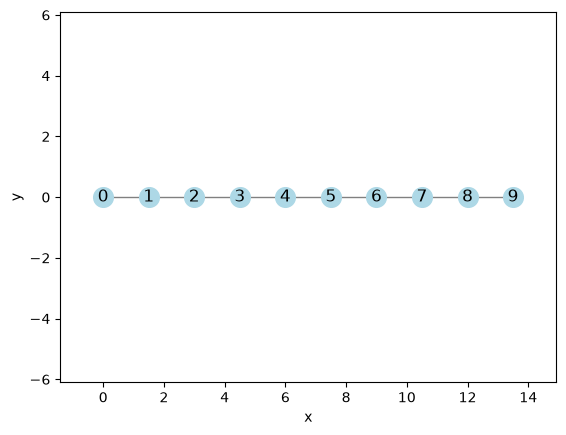

In [5]:
# Generate 1D grid graph
g = kn.misc.graph_grid(dimension=10, spacing=1.5)

# Options for plot of 2D graph
options = {
    'node_size'   : 200,         # node size
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

# Plot the graph
kn.view.plot_graph2d(g, **options)

### 1D grid - randomize positions

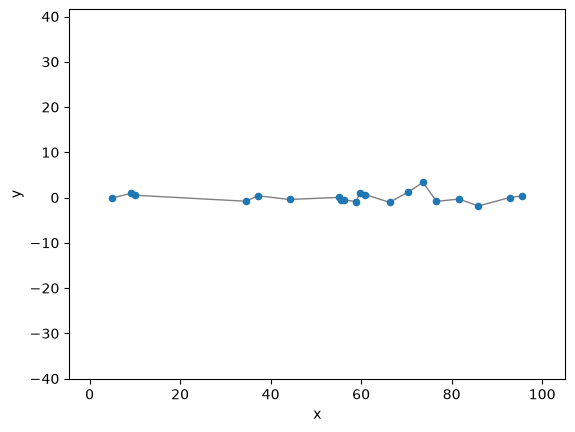

In [6]:
npts = 20  # number of points
lx = 100.0 # total length
y_std_noise = 1.e-2*lx # std. dev. of Gaussian noise along y-axis


# Generate 1D grid graph
g = kn.misc.graph_grid(dimension=npts)

# Set new positions
np.random.seed(32)
x = lx * np.sort(np.random.random(npts))
y = np.random.normal(size=npts, scale=y_std_noise) # add fluctuation along y axis (optional)
node_pos = {k:np.array([xk, yk]) for k, (xk, yk) in enumerate(zip(x, y))}
nx.set_node_attributes(g, node_pos, 'pos')

# Options for plot of 2D graph
options = {
    'node_size'   : 20,          # node size
    'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,       # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

# Plot the graph
kn.view.plot_graph2d(g, **options)


### 2D grid

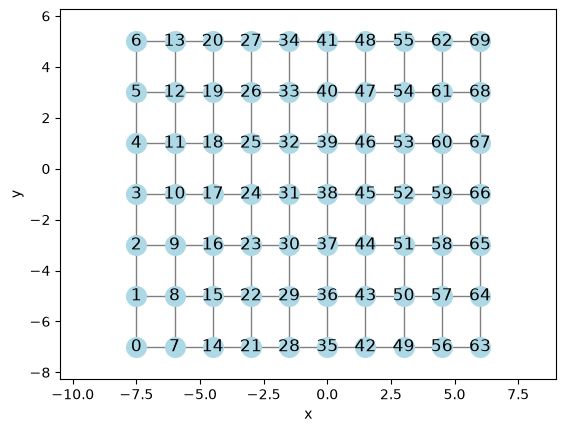

In [7]:
# Generate 2D grid graph
g = kn.misc.graph_grid(dimension=(10, 7), spacing=(1.5, 2.0), origin=(-7.5, -7.0))

# Options for plot of 2D graph
options = {
    'node_size'   : 200,         # node size
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

# Plot the graph
kn.view.plot_graph2d(g, **options)


### 3D grid

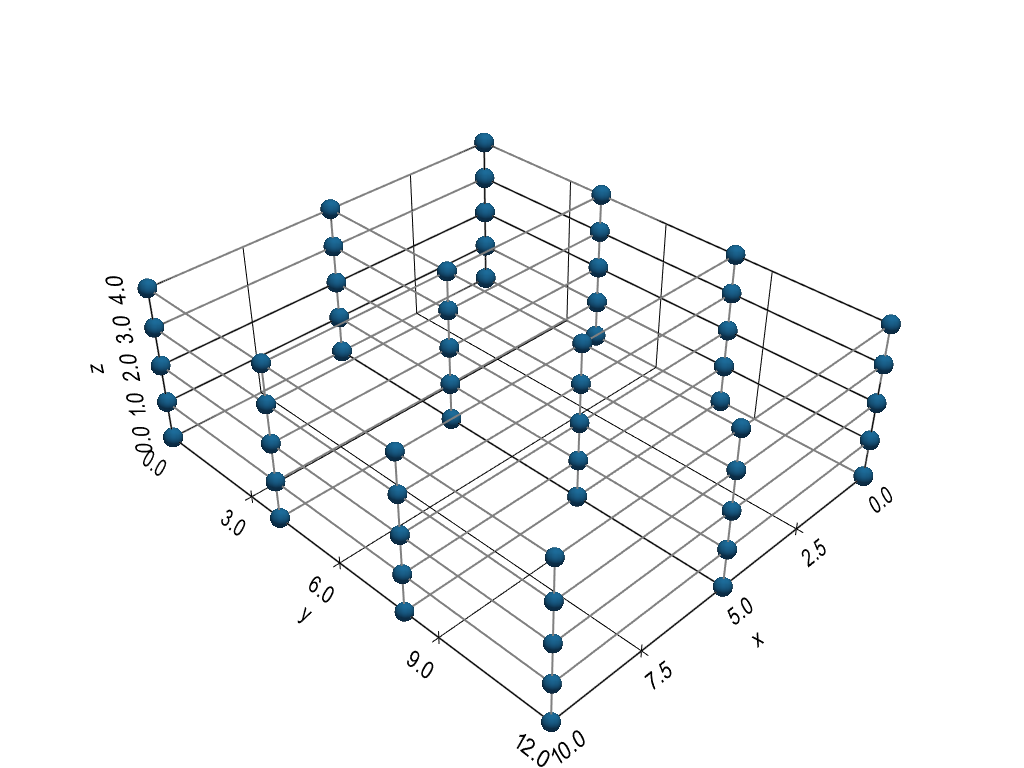

In [8]:
# Generate 3D grid graph
g = kn.misc.graph_grid(dimension=(3, 4, 5), spacing=(5.0, 4.0, 1.0))

# Plot the graph (based on pyvista)
# pp = pv.Plotter(notebook=False) # plot in a pop-up window
pp = pv.Plotter()

kn.view.pv_plot_graph(
    g,
    plotter=pp,
    options_nodes={'point_size': 20, 'color': 'tab:blue'},
    options_edges={'line_width': 2, 'color': 'gray'},
    show_grid=True,
    with_labels=True
)

pp.show()



### Honeycomb (2D)

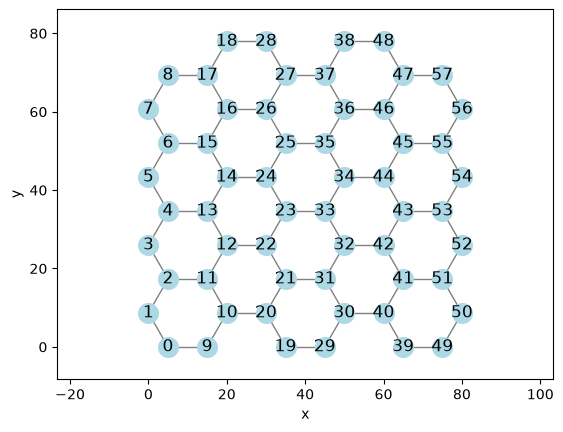

In [9]:
# Generate 2D honeycomb graph
g = kn.misc.graph_honeycomb(nrow=4, ncol=5, edge_length=10.0, integer_labels=True)

# Options for plot of 2D graph
options = {
    'node_size'   : 200,         # node size
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

# Plot the graph
kn.view.plot_graph2d(g, **options)

## 2. Graph of classic fractals

- The function `kn.misc.von_koch` allows to generate a graph representing a von Koch snow flake.
- The function `kn.misc.sierpinski` allows to generate a graph representing a Sierpinski triangle (Sierpinski gasket).

### Von Koch snow flakes

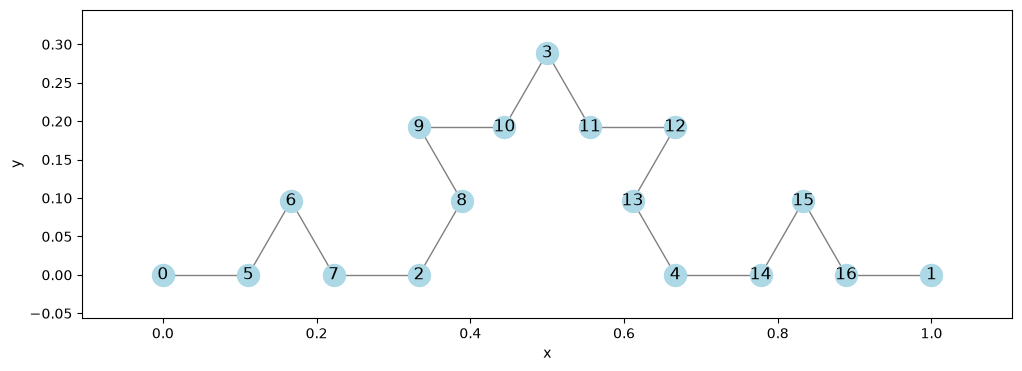

In [10]:
n = 2 # number of iterations
g = kn.misc.von_koch(n, close=False)

# Plot the graph
options = {
    'node_size'   : 250,         # node size
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

plt.figure(figsize=(12, 4))
kn.view.plot_graph2d(g, **options)
plt.show()


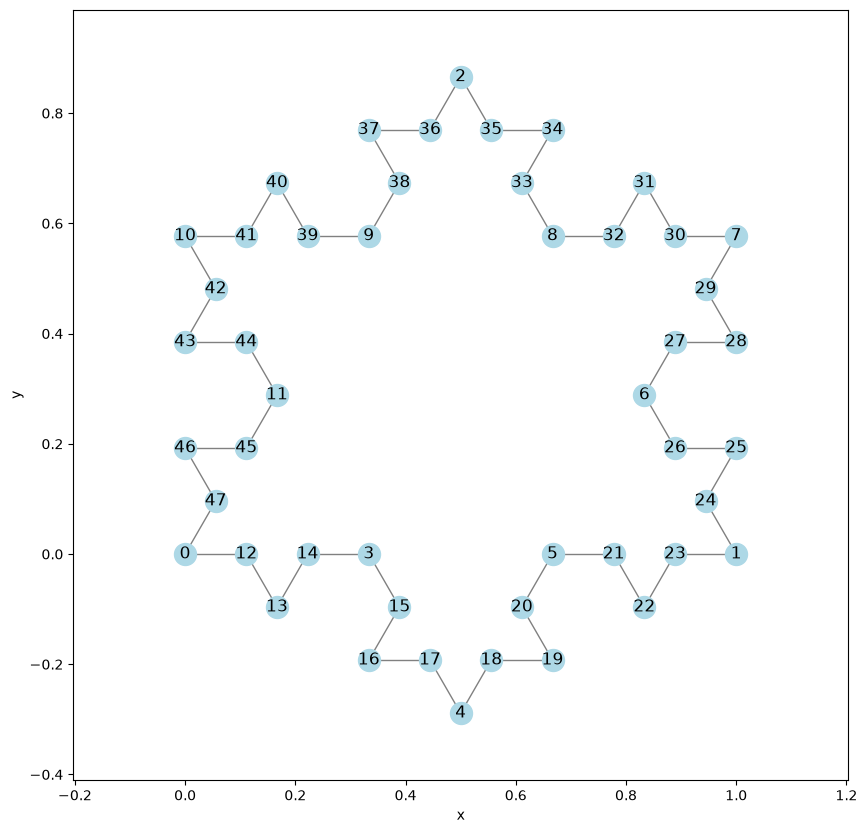

In [11]:
n = 2 # number of iterations
g = kn.misc.von_koch(n, close=True)

# Plot the graph
options = {
    'node_size'   : 250,         # node size
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

plt.figure(figsize=(10, 10))
kn.view.plot_graph2d(g, **options)
plt.show()


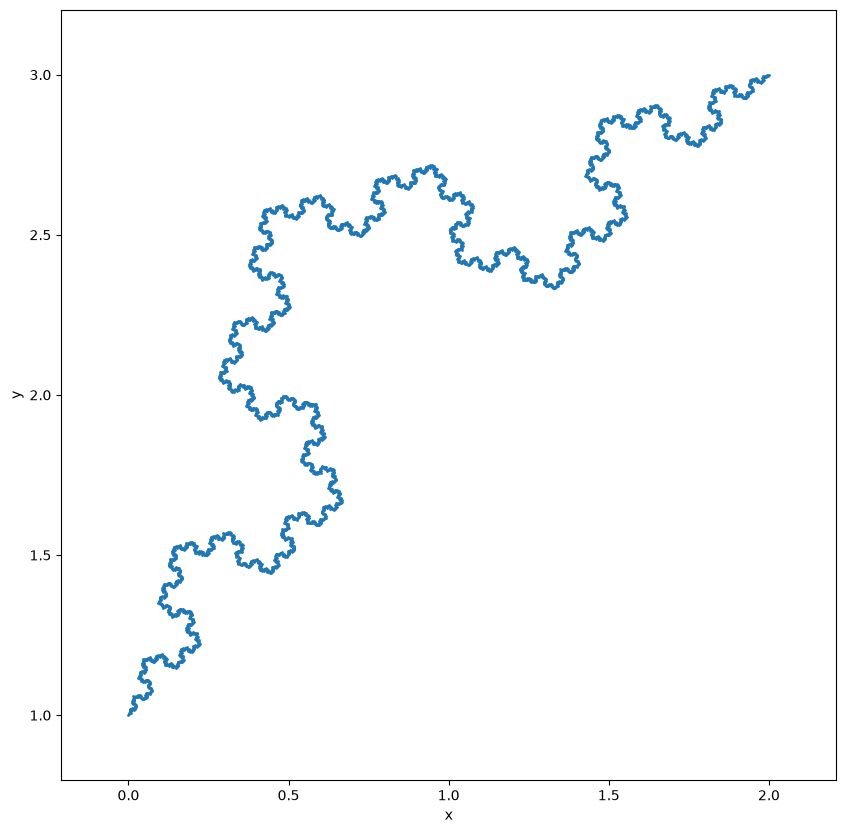

In [12]:
n = 6 # number of iterations
g = kn.misc.von_koch(n, first_edge=[(0.0, 1.0), (2.0, 3.0)], close=False)

# Plot the graph
options = {
    'node_size'   : 1,           # node size
    'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,       # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

plt.figure(figsize=(10, 10))
kn.view.plot_graph2d(g, **options)
plt.show()


### Sierpinski triangle

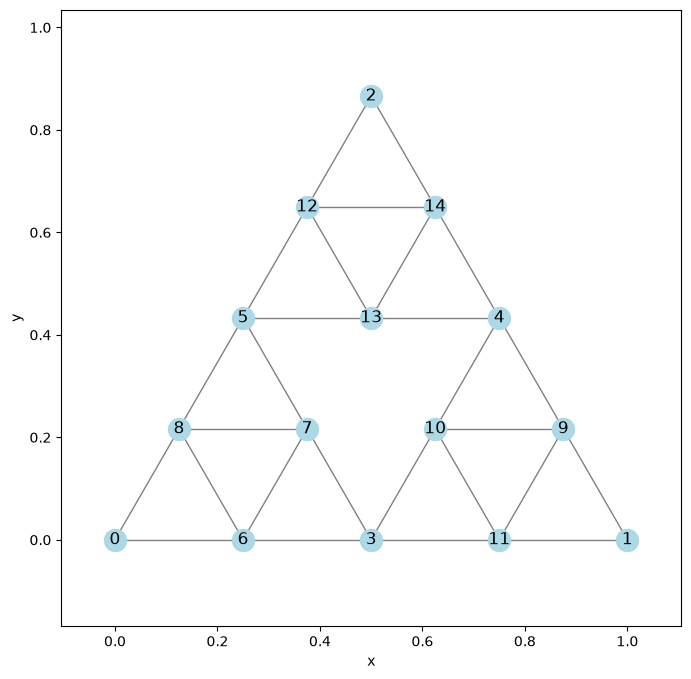

In [13]:
n = 2 # number of iterations
g = kn.misc.sierpinski(n)

# Plot the graph
options = {
    'node_size'   : 250,         # node size
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()


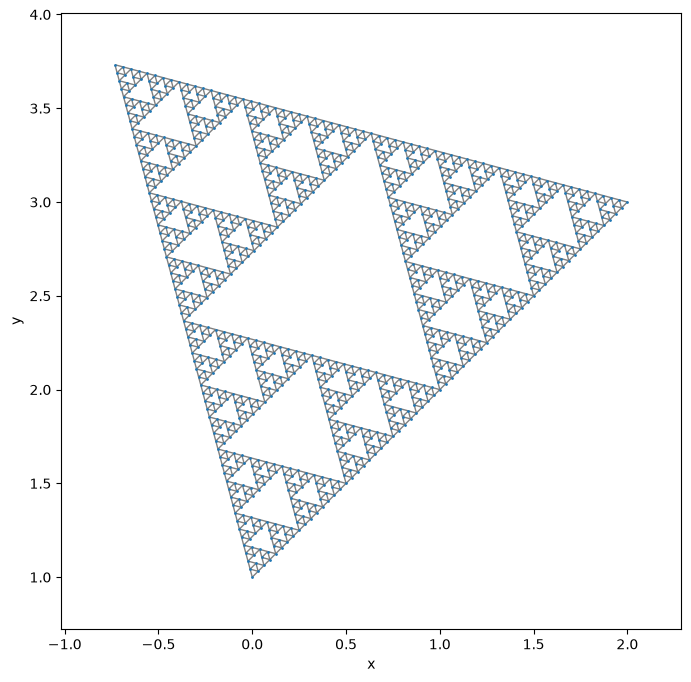

In [14]:
n = 6 # number of iterations
g = kn.misc.sierpinski(n, first_edge=[(0.0, 1.0), (2.0, 3.0)])

# Plot the graph
options = {
    'node_size'   : 1,           # node size
    'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,       # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()


## 3. Graph from Delaunay triangulation

The function `kn.misc.graph_from_delaunay_tri` allows to generate graph from an ensemble of points by building a Delaunay triangulation.

### Triangulation of points along a 2D grid

In [15]:
# Options for plot of 2D graph
options = {
    'node_size'   : 20,          # node size
    'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,       # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

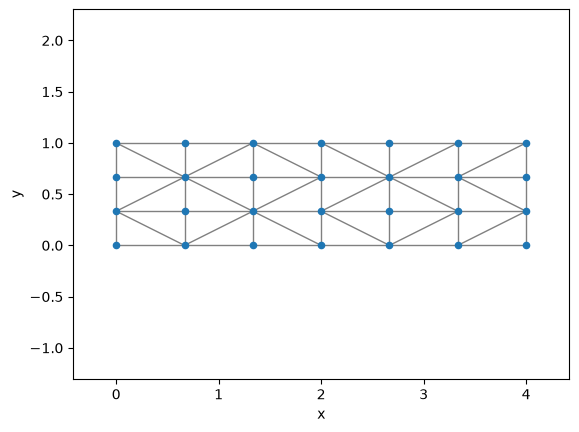

In [16]:
# Define points
yy, xx = np.meshgrid(np.linspace(0, 1, 4), np.linspace(0, 4, 7), indexing='ij')
points = np.vstack((xx.reshape(-1), yy.reshape(-1))).T

# Generate 2D graph from Delaunay triangulation of the points
g = kn.misc.graph_from_delaunay_tri(points)

# Options for plot of 2D graph
options = {
    'node_size'   : 20,          # node size
    'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,       # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

# Plot the graph
kn.view.plot_graph2d(g, **options)

### Triangulation of random points in 2D

In [17]:
# Options for plot of 2D graph
options = {
    'node_size'   : 20,          # node size
    'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,       # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

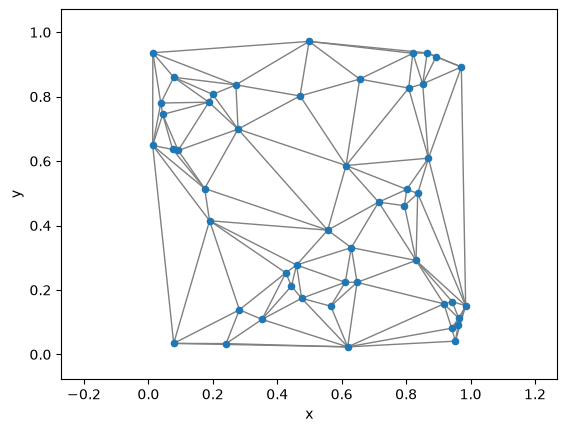

In [18]:
# Number of points and seed
npoints = 50
seed = 34

# Generate random points uniformly in [0, 1] x [0, 1]
np.random.seed(seed)
points = np.random.random(size=(npoints, 2))

# Generate 2D graph from Delaunay triangulation of the points
g = kn.misc.graph_from_delaunay_tri(points)

# Plot the graph
kn.view.plot_graph2d(g, **options)

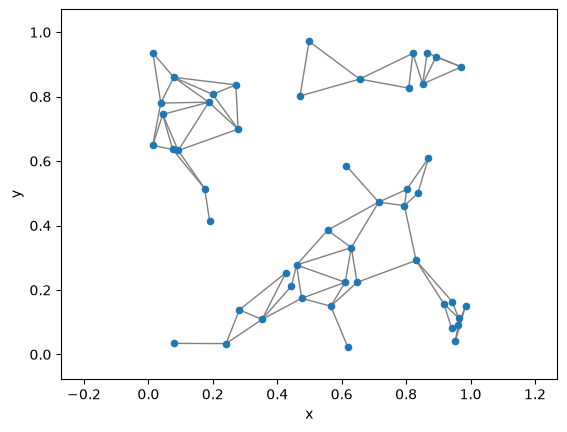

In [19]:
# Generate 2D graph from Delaunay triangulation of the points, 
# edges whose length are less (resp. greater) than a mininmal (resp. maximal) valuse are removed
g = kn.misc.graph_from_delaunay_tri(points, min_edge_len=0.05, max_edge_len=0.20)

# Plot the graph
kn.view.plot_graph2d(g, **options)

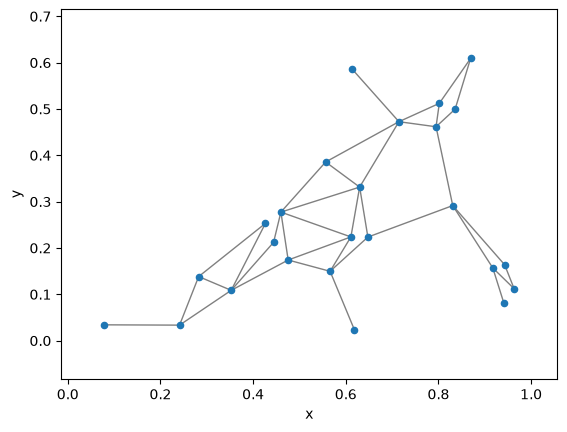

In [20]:
# Keep the largest connected component
g = kn.utils.get_list_of_connected_components(g, order='descending', renumbering_nodes=True)[0]

# Plot the graph
kn.view.plot_graph2d(g, **options)

## Triangulation of random points on the sphere (in 3D)

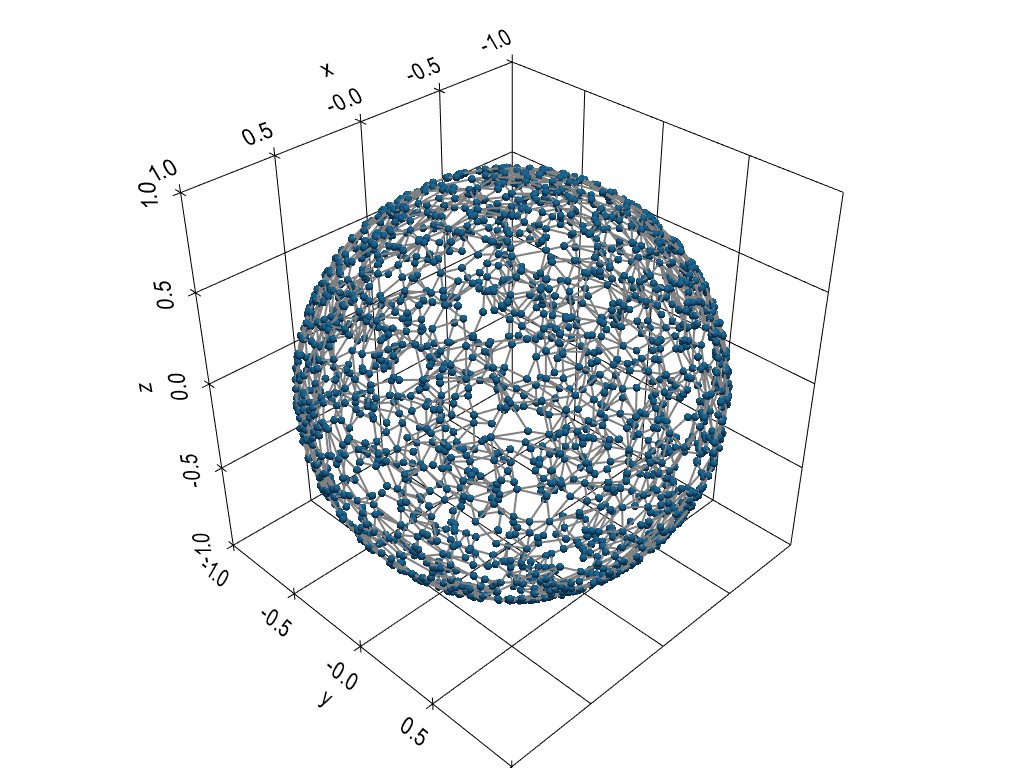

In [21]:
# Number of points and seed
npoints = 2000
radius = 1.0
seed = 39

# Generate random points uniformly on the sphere
np.random.seed(seed)
phi    = np.random.random(npoints)*2.0*np.pi
theta  = scipy.stats.anglit.rvs(scale=2, size=npoints)
points = radius * np.vstack((
                    np.cos(phi)*np.cos(theta), 
                    np.sin(phi)*np.cos(theta), 
                    np.sin(theta))).T

# Generate the graph
g = kn.misc.graph_from_delaunay_tri(points, max_edge_len=0.15)

# Keep the largest connected component
g = kn.utils.get_list_of_connected_components(g, order='descending', renumbering_nodes=True)[0]

# Plot the graph (based on pyvista)
#pp = pv.Plotter(notebook=False) # plot in a pop-up window
pp = pv.Plotter()

kn.view.pv_plot_graph(
    g,
    plotter=pp,
    options_nodes={'point_size': 8, 'color': 'tab:blue'},
    options_edges={'line_width': 2, 'color': 'gray'},
    show_grid=True,
    with_labels=False
)

pp.show()


## 4. Graph with points between two circles (2D)

The function `kn.misc.graph_between_circles` allows to generate a graph with points whose distance to the origin is between `r0` and `r1` (Delaunay triangulation is used).


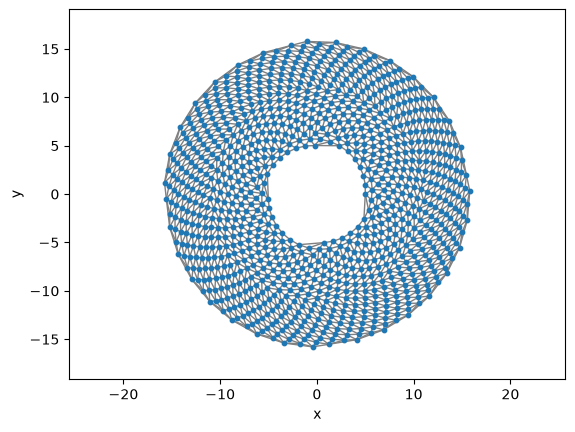

In [22]:
# Generate the graph
g = kn.misc.graph_between_circles(
        1000,            # number of points
        r0=5.0, r1=20.0, # inner and outer radius
        # r_edge_min=None, # minimal distance from the origin for the edges to be kept (r0 is used as default value)
        # angle_step=(1+np.sqrt(5))/2, # step size for the angle in radians (golden ratio is used as default value)
)

# Keep the largest connected component
g = kn.utils.get_list_of_connected_components(g, order='descending', renumbering_nodes=True)[0]


# Plot the graph
options = {
    'node_size'   : 10,          # node size
    'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,       # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}
kn.view.plot_graph2d(g, **options)


## 5. Graph with points on a sphere (3D)

The function `kn.misc.graph_on_sphere` allows to generate a graph with points on a sphere (Delaunay triangulation is used).


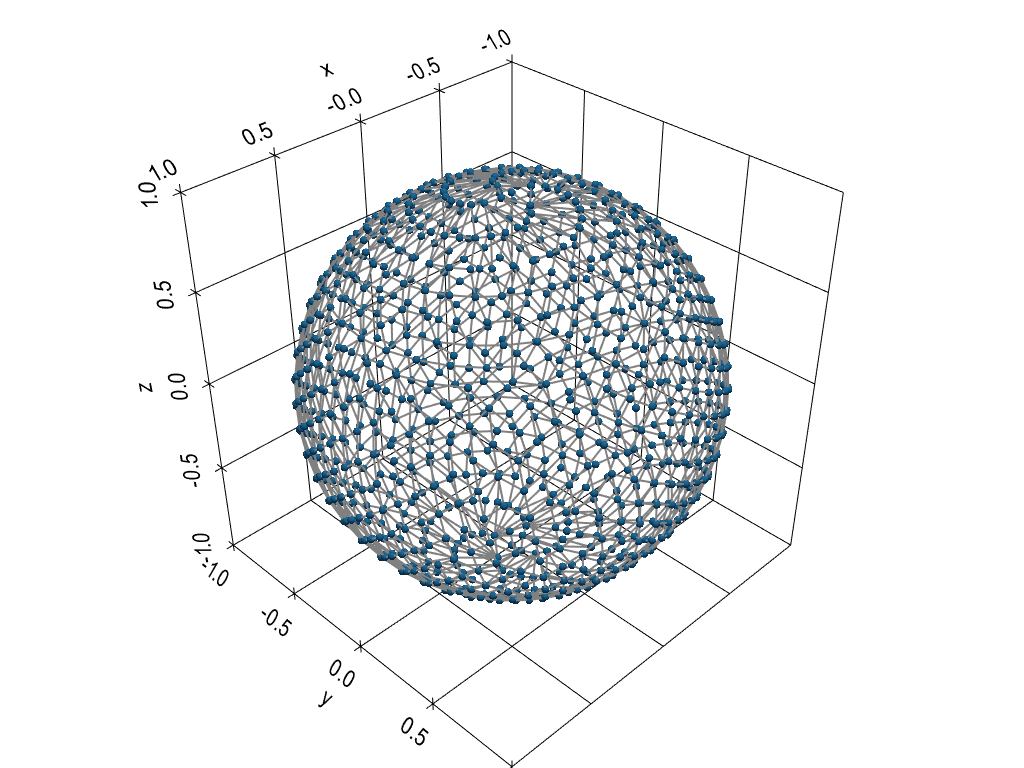

In [23]:
# Generate the graph
g = kn.misc.graph_on_sphere(
        1000,  # number of points
        r=1.0, # radius
        # r_edge_min=None, # minimal distance from the origin for the edges to be kept (0.99*r is used as default value)
        # angle_step=(1+np.sqrt(5))/2, # step size for the angle in radians (golden ratio is used as default value)
)

# Keep the largest connected component
g = kn.utils.get_list_of_connected_components(g, order='descending', renumbering_nodes=True)[0]

# Plot the graph (based on pyvista)
#pp = pv.Plotter(notebook=False) # plot in a pop-up window
pp = pv.Plotter()

kn.view.pv_plot_graph(
    g,
    plotter=pp,
    options_nodes={'point_size': 8, 'color': 'tab:blue'},
    options_edges={'line_width': 2, 'color': 'gray'},
    show_grid=True,
    with_labels=False
)

pp.show()


## 6. Graph of torus (2D-periodic grid embedded in 3D space)

The function `kn.misc.graph_torus` allows to generate a graph of a torus.


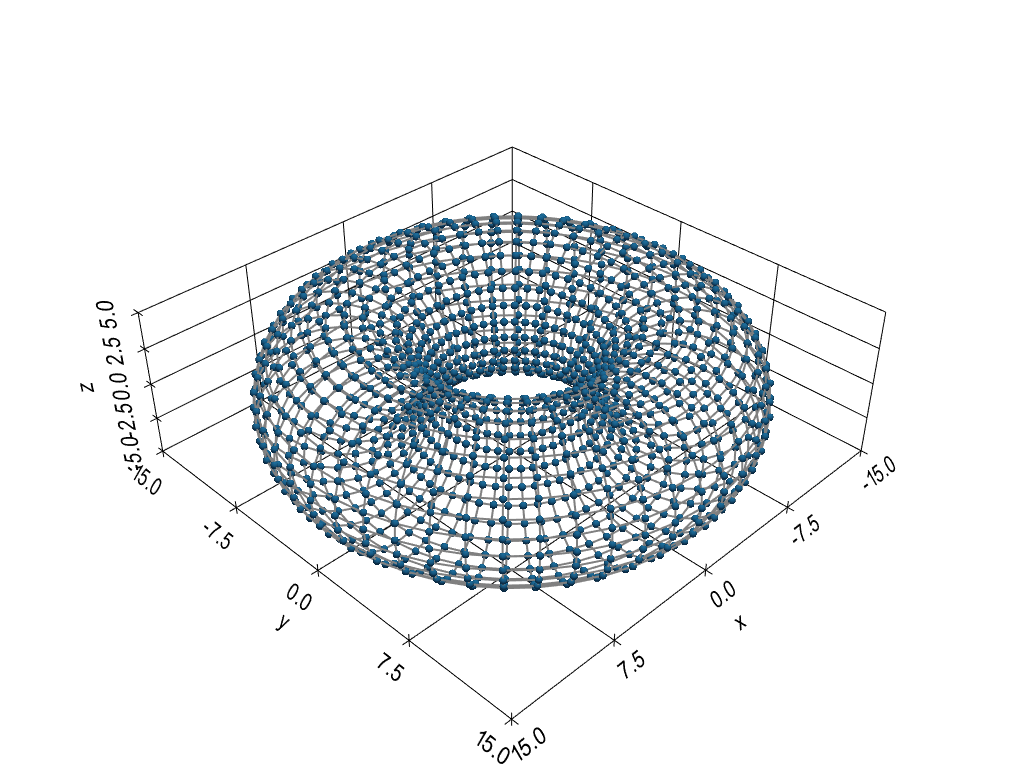

In [24]:
rh, rs = 10.0, 5.0 # radius of the "hole circle" and "section circle" of the torus
nh, ns = 50, 30    # number of nodes along the "hole circle" and "section circle" of the torus

g = kn.misc.graph_torus(rh, rs, nh, ns)

# Plot the graph (based on pyvista)
# pp = pv.Plotter(notebook=False) # plot in a pop-up window
pp = pv.Plotter()

kn.view.pv_plot_graph(
    g,
    plotter=pp,
    options_nodes={'point_size': 8, 'color': 'tab:blue'},
    options_edges={'line_width': 2, 'color': 'gray'},
    show_grid=True,
    with_labels=False
)

pp.show()



## 7. Graph from Diffusion-Limited Aggregation (DLA) - Brownian tree

A simulation consists in generating random walk of particles in a regular grid from a starting area to an ending (attracting) area, retaining the last position (beside the ending area) and adding this position to the ending area for the next particle. Then, a graph is computed from the aggregated particles in this grid.

The functions `kn.misc.dla_in_grid_2d` and `kn.misc.dla_in_grid_3d` allow to generate such networks in 2D and 3D respectively.

### Example 1 - 2D

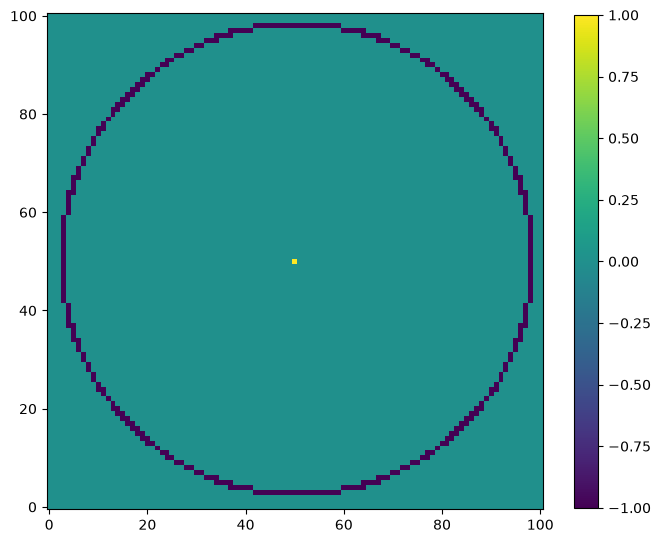

In [25]:
# Example 1

# Set input array with values
# * -1 : in starting area of the particles
# *  1 : in ending area
# *  0 : elsewhere (should include border of the array)

# Initialization
mx, my = 101, 101
in_arr = np.zeros((my, mx), dtype='int') 

# Ending area (index)
in_arr[my//2, mx//2] = 1

# Starting area (index)
yy, xx = np.meshgrid(np.arange(my), np.arange(mx), indexing='ij')
d2 = ((xx - mx/2)/mx)**2 + ((yy-my/2)/my)**2
in_arr[np.all((d2 < 0.23, d2 > 0.22), axis=0)] = -1

# Plot input array
plt.figure(figsize=(8, 8))
plt.imshow(in_arr, origin='lower')
plt.colorbar(shrink=.8)
plt.show()

In [26]:
nparticles = 1000
seed = 203

t1 = time.time()
g, dla_arr = kn.misc.dla_in_grid_2d(
                in_arr,
                nparticles, 
                nparticles_try_max=100*nparticles, 
                n_random_walk_step_max=10000,
                stop_at_percolation=False, 
                link_to_all_neighbors=False,
                sx=1.0, 
                sy=1.0,
                pos_attr='pos',
                dla_step_attr='dla_step',
                seed=seed, 
                inplace=False, 
                return_array=True,
                verbose=1)
t2 = time.time()

print(f'Elapsed time : {t2-t1:.2g} sec')


Compute DLA simulation array
Current particle 1 over 1000 ; attempt 1 over 100000
Current particle 1 over 1000 ; attempt 2 over 100000
Current particle 1 over 1000 ; attempt 3 over 100000
Current particle 1 over 1000 ; attempt 4 over 100000
Current particle 1 over 1000 ; attempt 5 over 100000
Current particle 1 over 1000 ; attempt 6 over 100000
Current particle 1 over 1000 ; attempt 7 over 100000
Current particle 1 over 1000 ; attempt 8 over 100000
Current particle 1 over 1000 ; attempt 9 over 100000
Current particle 1 over 1000 ; attempt 10 over 100000
Current particle 1 over 1000 ; attempt 11 over 100000
Current particle 1 over 1000 ; attempt 12 over 100000
Current particle 1 over 1000 ; attempt 13 over 100000
Current particle 1 over 1000 ; attempt 14 over 100000
Current particle 1 over 1000 ; attempt 15 over 100000
Current particle 1 over 1000 ; attempt 16 over 100000
Current particle 1 over 1000 ; attempt 17 over 100000
Current particle 1 over 1000 ; attempt 18 over 100000
Current 

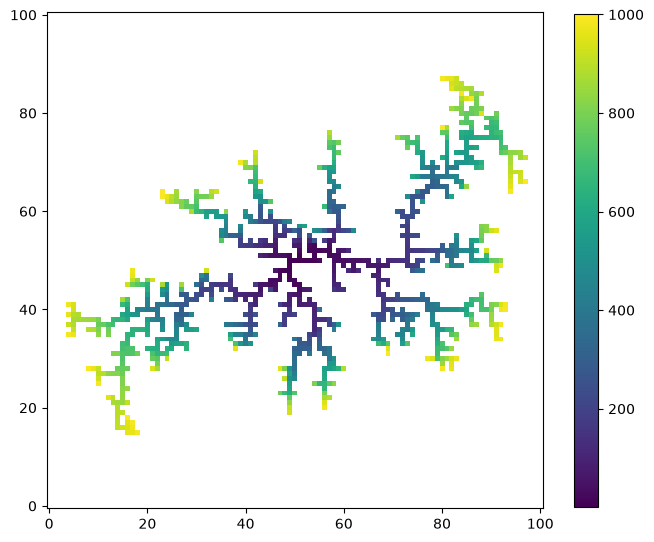

In [27]:
# Plot DLA simulation array
# dla_arr_cp = np.copy(dla_arr).astype('float')
dla_arr = dla_arr.astype('float')
dla_arr[dla_arr<=0] = np.nan

plt.figure(figsize=(8, 8))
plt.imshow(dla_arr, origin='lower', interpolation='none')
plt.colorbar(shrink=.8)
plt.show()

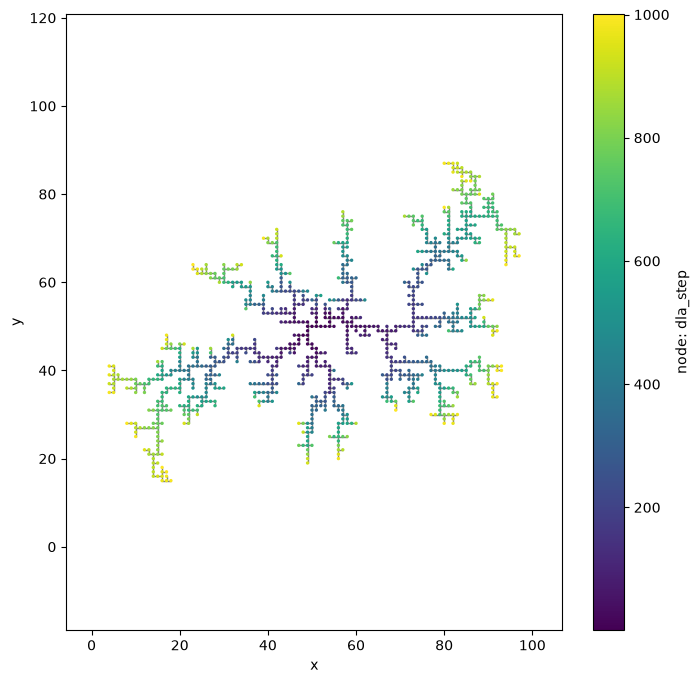

In [28]:
# Plot the graph
options = {
    'node_size'   : 2,           # node size
    'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'cmap'        : 'viridis',   # node color map (for attribute values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,       # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, node_attr='dla_step', **options)
plt.show()


### Example 2 - 2D

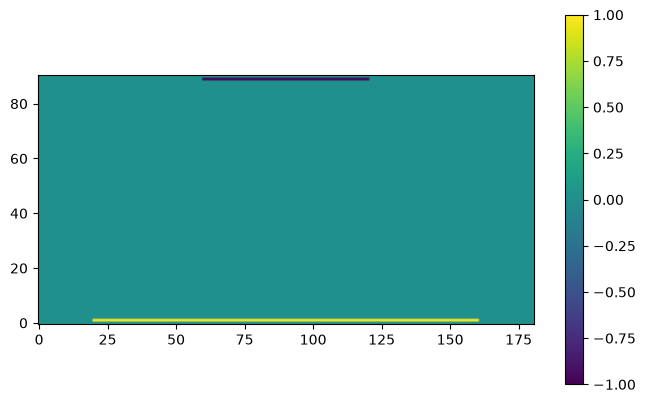

In [29]:
# Example 2

# Set input array with values
# * -1 : in starting area of the particles
# *  1 : in ending area
# *  0 : elsewhere (should include border of the array)

# Initialization
mx, my = 181, 91
in_arr = np.zeros((my, mx), dtype='int') 

# Ending area (index)
in_arr[1, 20:161] = 1

# Starting area (index)
in_arr[-2, 60:121] = -1

# Plot input array
plt.figure(figsize=(8, 6))
plt.imshow(in_arr, origin='lower')
plt.colorbar(shrink=.8)
plt.show()

In [30]:
nparticles = 10000
seed = 2203

t1 = time.time()
g, dla_arr = kn.misc.dla_in_grid_2d(
                in_arr,
                nparticles, 
                nparticles_try_max=500*nparticles, 
                n_random_walk_step_max=100000, 
                stop_at_percolation=True, 
                link_to_all_neighbors=False,
                sx=1.0, 
                sy=1.0,
                pos_attr='pos',
                dla_step_attr='dla_step',
                seed=seed, 
                inplace=False, 
                return_array=True,
                verbose=1)
t2 = time.time()

print(f'Elapsed time : {t2-t1:.2g} sec')


Compute DLA simulation array
Current particle 1 over 10000 ; attempt 1 over 5000000
Current particle 1 over 10000 ; attempt 2 over 5000000
Current particle 1 over 10000 ; attempt 3 over 5000000
Current particle 1 over 10000 ; attempt 4 over 5000000
Current particle 1 over 10000 ; attempt 5 over 5000000
Current particle 1 over 10000 ; attempt 6 over 5000000
Current particle 1 over 10000 ; attempt 7 over 5000000
Current particle 1 over 10000 ; attempt 8 over 5000000
Current particle 1 over 10000 ; attempt 9 over 5000000
Current particle 1 over 10000 ; attempt 10 over 5000000
Current particle 1 over 10000 ; attempt 11 over 5000000
Current particle 1 over 10000 ; attempt 12 over 5000000
Current particle 1 over 10000 ; attempt 13 over 5000000
Current particle 1 over 10000 ; attempt 14 over 5000000
Current particle 1 over 10000 ; attempt 15 over 5000000
Current particle 1 over 10000 ; attempt 16 over 5000000
Current particle 1 over 10000 ; attempt 17 over 5000000
Current particle 1 over 1000

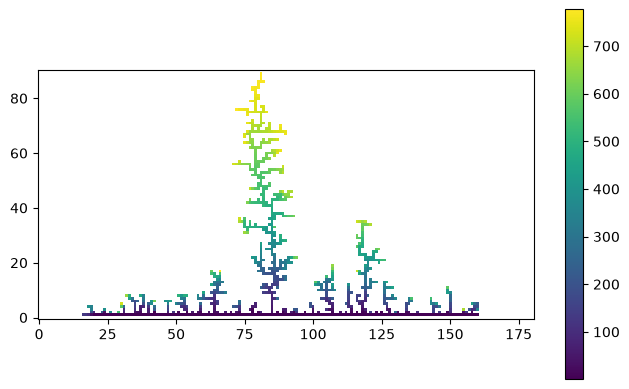

In [31]:
# Plot DLA simulation array
# dla_arr_cp = np.copy(dla_arr).astype('float')
dla_arr = dla_arr.astype('float')
dla_arr[dla_arr<=0] = np.nan

plt.figure(figsize=(8, 6))
plt.imshow(dla_arr, origin='lower', interpolation='none')
plt.colorbar(shrink=.8)
plt.show()

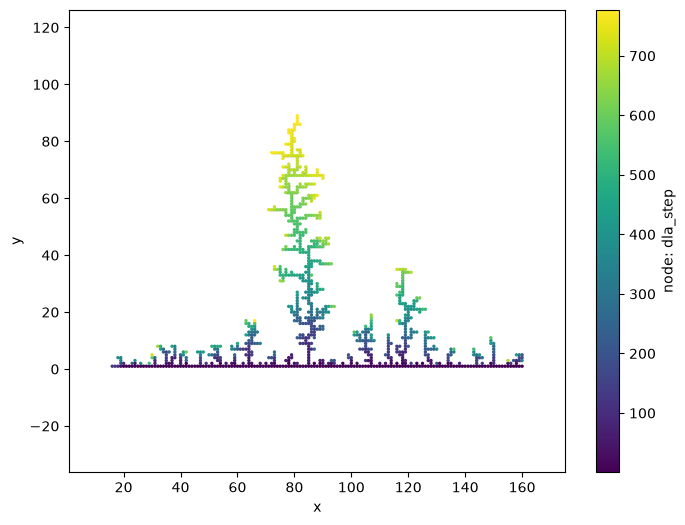

In [32]:
# Plot the graph
options = {
    'node_size'   : 2,           # node size
    'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'cmap'        : 'viridis',   # node color map (for attribute values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,       # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

plt.figure(figsize=(8, 6))
kn.view.plot_graph2d(g, node_attr='dla_step', **options)
plt.show()


### Example 3 - 3D

In [33]:
# Example 3

# Set input array with values
# * -1 : in starting area of the particles
# *  1 : in ending area
# *  0 : elsewhere (should include border of the array)

# Initialization
mx, my, mz = 61, 61, 61
in_arr = np.zeros((mz, my, mx), dtype='int') 

# Ending area (index)
in_arr[mz//2, my//2, mx//2] = 1

# Starting area (index)
zz, yy, xx = np.meshgrid(np.arange(mz), np.arange(my), np.arange(mx), indexing='ij')
d2 = ((xx - mx/2)/mx)**2 + ((yy-my/2)/my)**2 + ((zz-mz/2)/mz)**2
in_arr[np.all((d2 < 0.23, d2 > 0.2), axis=0)] = -1


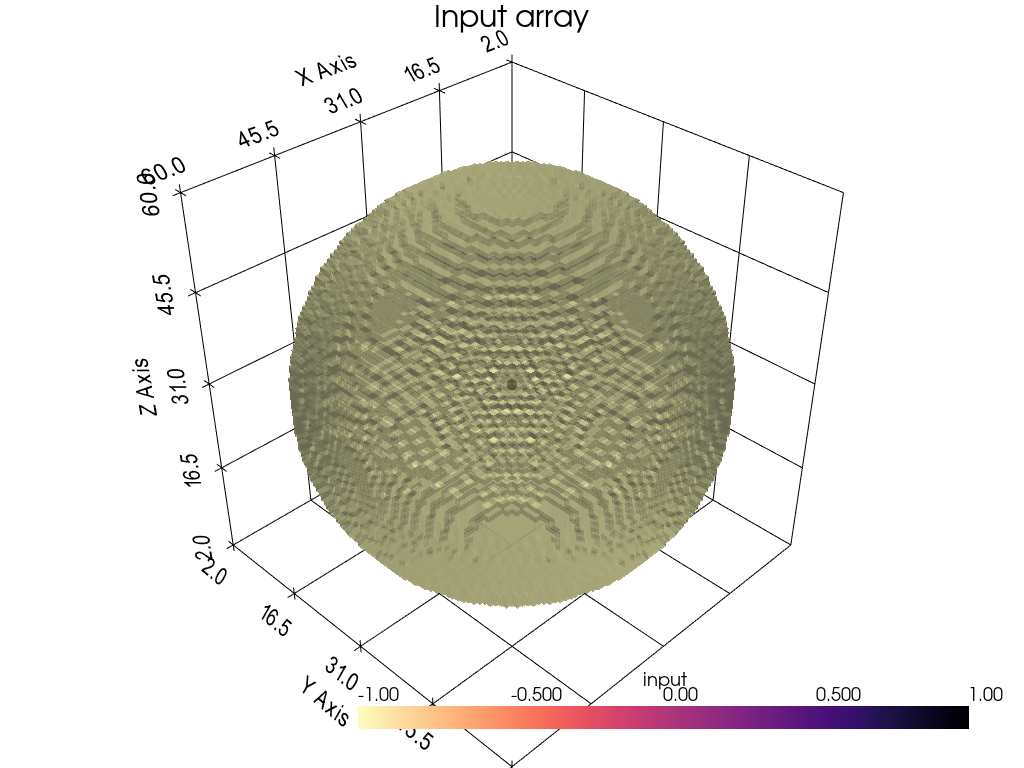

In [34]:
# Plot input array (based on pyvista)

pg = pv.ImageData(dimensions=(mx+1, my+1, mz+1))
pg.cell_data['input'] = in_arr.astype('float').flatten()
np.putmask(pg.cell_data['input'], pg.cell_data['input']==0, np.nan)

# pp = pv.Plotter(notebook=False) # plot in a pop-up window
pp = pv.Plotter()
pp.add_mesh(pg.threshold(), cmap='magma_r', opacity=0.7)
pp.show_grid()
#pp.show_bounds()
pp.add_text('Input array', position='upper_edge', font_size=12, color='black')
pp.show()

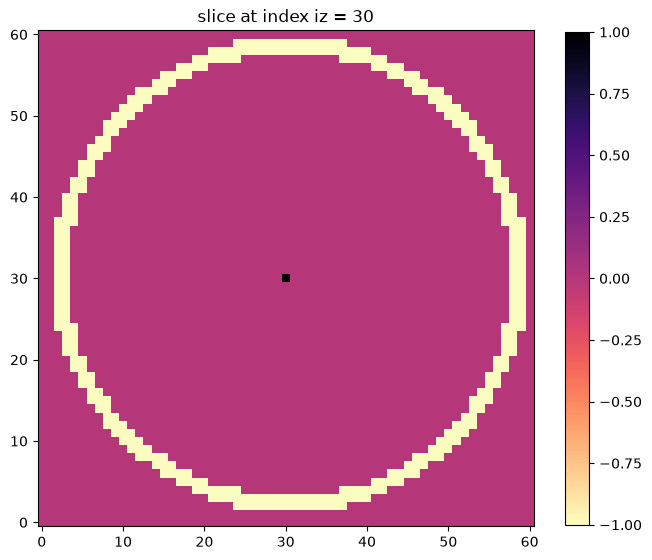

In [35]:
# Plot slice of input array
plt.figure(figsize=(8, 8))
plt.imshow(in_arr[mz//2,:,:], origin='lower', cmap='magma_r')
plt.colorbar(shrink=.8)
plt.title(f'slice at index iz = {mz//2}')
plt.show()


In [36]:
nparticles = 1000
seed = 213

t1 = time.time()
g = kn.misc.dla_in_grid_3d(
                in_arr,
                nparticles, 
                nparticles_try_max=100*nparticles, 
                n_random_walk_step_max=10000,
                stop_at_percolation=False, 
                link_to_all_neighbors=False,
                sx=1.0, 
                sy=1.0,
                pos_attr='pos',
                dla_step_attr='dla_step',
                seed=seed, 
                inplace=False, 
                return_array=False,
                verbose=1)
t2 = time.time()

print(f'Elapsed time : {t2-t1:.2g} sec')


Compute DLA simulation array
Current particle 1 over 1000 ; attempt 1 over 100000
Current particle 1 over 1000 ; attempt 2 over 100000
Current particle 1 over 1000 ; attempt 3 over 100000
Current particle 1 over 1000 ; attempt 4 over 100000
Current particle 1 over 1000 ; attempt 5 over 100000
Current particle 1 over 1000 ; attempt 6 over 100000
Current particle 1 over 1000 ; attempt 7 over 100000
Current particle 1 over 1000 ; attempt 8 over 100000
Current particle 1 over 1000 ; attempt 9 over 100000
Current particle 1 over 1000 ; attempt 10 over 100000
Current particle 1 over 1000 ; attempt 11 over 100000
Current particle 1 over 1000 ; attempt 12 over 100000
Current particle 1 over 1000 ; attempt 13 over 100000
Current particle 1 over 1000 ; attempt 14 over 100000
Current particle 1 over 1000 ; attempt 15 over 100000
Current particle 1 over 1000 ; attempt 16 over 100000
Current particle 1 over 1000 ; attempt 17 over 100000
Current particle 1 over 1000 ; attempt 18 over 100000
Current 

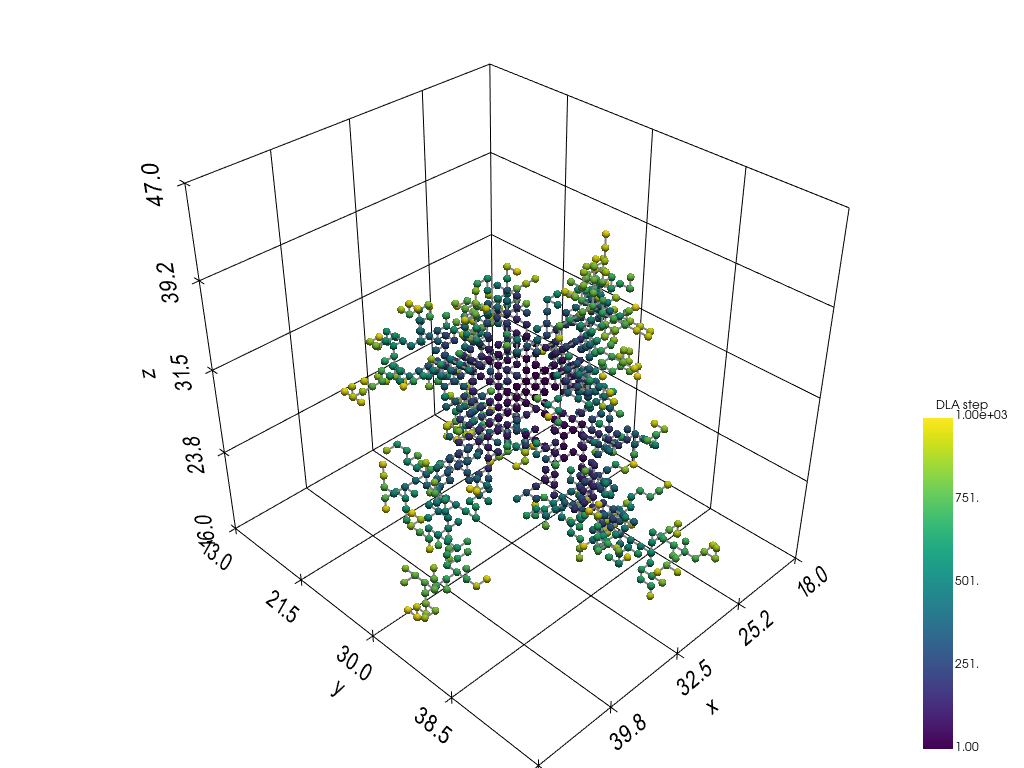

In [37]:
# Plot the graph (based on pyvista)
#pp = pv.Plotter(notebook=False) # plot in a pop-up window
pp = pv.Plotter()

kn.view.pv_plot_graph(
    g,
    plotter=pp,
    node_attr='dla_step',
    options_nodes={'point_size': 8, 'cmap': 'viridis'},
    options_edges={'line_width': 2, 'color': 'gray'},
    show_grid=True,
    with_labels=False,
    options_node_colorbar={'title': 'DLA step', 'label_font_size': 12, 'title_font_size': 12, 'vertical': True}
)

pp.show()